In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [4]:
df=pd.read_csv("student_marks.csv")
df.head()

,study_hours,attendance,marks
0,7.1,95.4,95.3
1,4.2,85.0,67.8
2,7.8,63.3,82.9
3,6.4,98.5,88.2
4,1.3,88.9,55.1


In [5]:
print("Shape:",df.shape)
print("columns",df.columns)

df.info()

df.describe

Shape: (100, 3)
columns Index(['study_hours', 'attendance', 'marks'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   study_hours  100 non-null    float64
 1   attendance   100 non-null    float64
 2   marks        100 non-null    float64
dtypes: float64(3)
memory usage: 2.5 KB


<bound method NDFrame.describe of     study_hours  attendance  marks
0           7.1        95.4   95.3
1           4.2        85.0   67.8
2           7.8        63.3   82.9
3           6.4        98.5   88.2
4           1.3        88.9   55.1
..          ...         ...    ...
95          5.9        59.0   70.1
96          3.6        80.0   71.3
97          1.2        93.7   42.0
98          1.5        59.8   41.2
99          8.7        65.5   90.3

[100 rows x 3 columns]>

In [6]:
df.isnull().sum()

study_hours    0
attendance     0
marks          0
dtype: int64

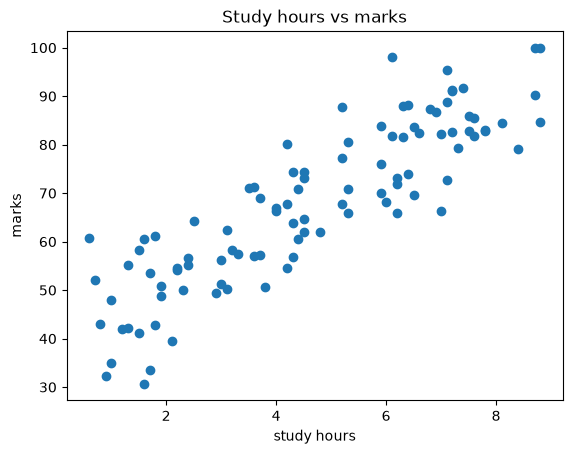

In [7]:
plt.scatter(df['study_hours'],df['marks'])

plt.xlabel("study hours")
plt.ylabel("marks")
plt.title("Study hours vs marks")

plt.show()

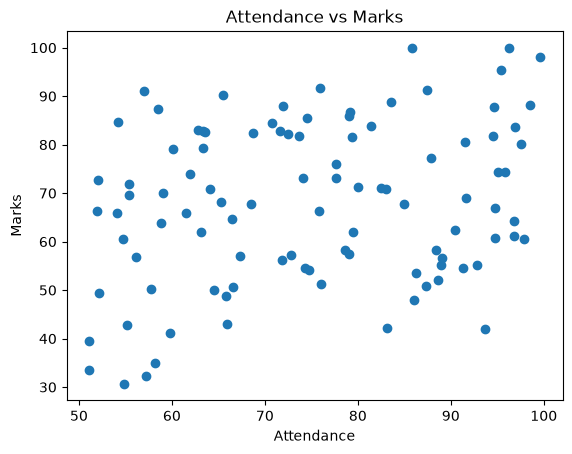

In [8]:
# Attendance vs Marks
plt.scatter(df['attendance'], df['marks'])

plt.xlabel("Attendance")
plt.ylabel("Marks")
plt.title("Attendance vs Marks")

plt.show()

In [9]:
x=df[['study_hours','attendance']]
y=df['marks']

print("features")

display(x.head())


print("target")
display(y.head())

features


,study_hours,attendance
0,7.1,95.4
1,4.2,85.0
2,7.8,63.3
3,6.4,98.5
4,1.3,88.9


target


0    95.3
1    67.8
2    82.9
3    88.2
4    55.1
Name: marks, dtype: float64

In [10]:
x_train,x_test,y_train,y_test=train_test_split(x,
                                               y,
                                               test_size=0.2,
                                               random_state=42)

print("training data",x_train.shape)
print("testing data",x_test.shape)

training data (80, 2)
testing data (20, 2)


In [11]:
model=LinearRegression()
model.fit(x_train,y_train)

print("model trained")

print(model.intercept_)
print(model.coef_)

model trained
4.094819112013717
[6.74569801 0.4329113 ]


In [12]:
y_pred=model.predict(x_test)

comparison=pd.DataFrame({
    "Actual marks":y_test.values,
    "predicted marks":y_pred
})

comparison.head(10)

,Actual marks,predicted marks
0,48.7,45.397209
1,73.2,79.555355
2,50.1,47.532703
3,79.4,80.741700
4,81.7,87.267687
5,65.9,69.338648
6,84.6,86.920754
7,81.7,86.153695
8,57.3,60.569844
9,95.3,93.289013


In [14]:
# Actual aur predicted marks ke beech error calculate karna

# MAE: Average absolute error
mae = mean_absolute_error(y_test, y_pred)

# MSE: Average squared error
mse = mean_squared_error(y_test, y_pred)

# RMSE: Square root of MSE
rmse = np.sqrt(mse)

# R2: Model kitna variation explain karta hai
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 3.88
MSE: 22.82
RMSE: 4.78
R2 Score: 0.9085


In [15]:
# Ek naye student ka data create kar rahe hain

new_student = pd.DataFrame({
    'study_hours': [6],
    'attendance': [85]
})

# Trained model se marks predict karna
prediction = model.predict(new_student)

# Predicted result display karna
print("Expected Marks:", round(prediction[0], 2))

Expected Marks: 81.37


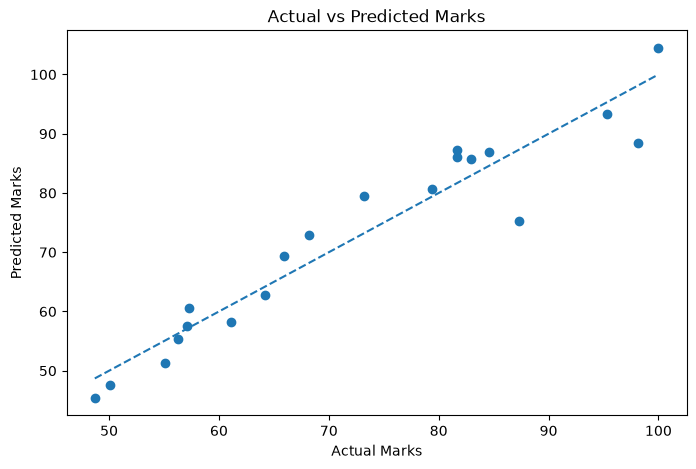

In [16]:
# Figure create karna
plt.figure(figsize=(8, 5))

# Actual aur predicted marks plot karna
plt.scatter(y_test, y_pred)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Marks")

plt.show()